# ניתוח מאגר ECG לזיהוי משתתפים

מחברת זו בודקת את הנתונים המקומיים בלבד: מבנה המאגר, מטא־דאטה, מספר הקלטות, גיל, מין ומשך. אין כאן אימון מודל או שינוי של נתוני המקור.

בחרו **Run All** כדי להפיק מחדש את הטבלאות והגרפים. הפלטים אינם שמורים מראש: הם יחושבו מהקבצים שלכם. גיל ומין נספרים ברמת משתתף, ולא פעם לכל הקלטה.

הדרישות: Python 3.10 ומעלה, pandas, numpy, matplotlib, wfdb ו־python-bidi. אם חסרה ספרייה, הסירו את סימן ההערה בתא הבא והריצו אותו. התקנה היא פעולה נפרדת לפי בחירתכם.

In [1]:
# התקנה רק במידת הצורך ובבחירה מפורשת שלכם:
# %pip install pandas numpy matplotlib wfdb python-bidi

from pathlib import Path
from collections import Counter
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from bidi.algorithm import get_display
except ImportError:
    raise ImportError("Install python-bidi using the installation cell above, then rerun.")

pd.set_option("display.max_rows", 100)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120, "axes.unicode_minus": False})
def he(text):
    """התאמת טקסט עברי לתצוגה ב־Matplotlib, בלי שינוי הנתונים."""
    return get_display(str(text))


## מבנה המאגר והנתיבים

המחברת נשמרת בשורש הפרויקט. מתחתיו נמצאת תיקיית `ecg-id-database-1.0.0`, ובה `Person_01` עד `Person_90`. הקוד תומך גם בהפעלת Jupyter מתוך תיקיית המאגר עצמה; אם סביבת העבודה נמצאת במקום אחר, יש להגדיר במפורש את `PROJECT_ROOT` בתא הבא.

לכל הקלטה שלושה קבצים: **HEA** הוא כותרת טקסט עם פרטי הדגימה והמשתתף; **DAT** מכיל דגימות בינאריות; **ATR** מכיל סימוני אירועים. לפי README ו־ANNOTATORS, אלה סימוני פסגות R ו־T אוטומטיים שלא נבדקו ידנית. קובצי PNG ו־SHTML הם חומרי תיעוד, ולא הקלטות נוספות.

שני ערוצי האות הם ECG I המקורי וגרסה מסוננת שלו — אותה מדידה, ולא שתי הקלטות עצמאיות.

In [2]:
PROJECT_ROOT = Path.cwd().resolve()  # אפשר להחליף בנתיב מפורש לשורש הפרויקט
candidates = [PROJECT_ROOT / "ecg-id-database-1.0.0", PROJECT_ROOT]
DATA_ROOT = next((p for p in candidates if p.is_dir() and any(p.glob("Person_*/*.hea"))), None)
if DATA_ROOT is None:
    raise FileNotFoundError("ECG headers not found. Set PROJECT_ROOT to the project folder.")
headers = sorted(DATA_ROOT.glob("Person_*/*.hea"))
print("Dataset folder:", DATA_ROOT.name)
print("HEA files:", len(headers))
file_counts = Counter(p.suffix.lower() or "(ללא סיומת)" for p in DATA_ROOT.rglob("*") if p.is_file())
display(pd.DataFrame(sorted(file_counts.items()), columns=["סיומת", "מספר קבצים"]))
for name in ["README", "ANNOTATORS"]:
    path = DATA_ROOT / name
    if path.is_file():
        print("\n" + name + "\n" + path.read_text(encoding="utf-8", errors="replace"))


Dataset folder: ecg-id-database-1.0.0
HEA files: 310


,סיומת,מספר קבצים
0,(ללא סיומת),3
1,.atr,310
2,.dat,310
3,.hea,310
4,.pdf,1
5,.png,60
6,.shtml,6
7,.txt,1



README

Database name: Biometric human identification ECG database  (ecgiddb)


Creator: 
Tatiana Lugovaya
for master's thesis "Biometric human identification based on ECG" in 2005
Department of Applied Mathematics and Computer Science
Electrotechnical University "LETI", Saint-Petersburg, Russian Federation


Database contains 310 ECG recordings, obtained from 90 persons:
- each recording contain 20-second I-lead ECG signal;
- 10 beats in every recording are annotated (unaudited R- and T-wave peaks annotations from an automated detector);
- signals were digitized at 500 Hz with 12-bit resolution;
- number of records for each person vary from 2 (collected during one day) to 20 (collected periodically during 6 months);
- each recording is supplied with an information containing age, gender and record date;
- records were obtained from volunteers among students, colleagues and friends (44 men and 46 women aged from 13 to 75 years);


Collected raw data is rather noisy and contain both hi

## קריאת המטא־דאטה מתוך HEA

השורה הראשונה כוללת שם הקלטה, מספר ערוצים, תדר דגימה ומספר דגימות לכל ערוץ. משך ההקלטה מחושב כמספר הדגימות חלקי תדר הדגימה. שורות הערוצים כוללות שם קובץ, פורמט אחסון, מקדם המרה, רזולוציית ממיר ותיאור ערוץ. פורמט אחסון 16 אינו אומר שרזולוציית המדידה היא 16 ביט.

הקוד אינו משלים גיל או מין חסרים. ערכים חסרים, לא תקינים, שדות כפולים או סתירות יוצגו לבדיקה. זיהוי המשתתף מגיע משם התיקייה; `rec_1` לבדו אינו מזהה ייחודי במאגר.

In [3]:
def parse_header(path):
    lines = path.read_text(encoding="utf-8").splitlines()
    content = [line.strip() for line in lines if line.strip() and not line.lstrip().startswith("#")]
    first = content[0].split()
    if len(first) < 4:
        raise ValueError(f"Incomplete record header: {path.relative_to(DATA_ROOT)}")
    record, n_channels = first[0], int(first[1])
    fs = float(first[2].split("/")[0])
    n_samples = int(first[3])
    if fs <= 0 or n_samples <= 0 or n_channels <= 0:
        raise ValueError(f"Invalid dimensions: {path.relative_to(DATA_ROOT)}")
    metadata = {}
    for line in lines:
        match = re.match(r"^#\s*([^:]+):\s*(.*?)\s*$", line)
        if match:
            key, value = match.groups()
            if key in metadata:
                raise ValueError(f"Duplicate metadata field {key}: {path.name}")
            metadata[key] = value
    age_text = metadata.get("Age", "")
    age = int(age_text) if re.fullmatch(r"\d+", age_text) else pd.NA
    sex = metadata.get("Sex", "").strip().lower() or pd.NA
    date_text = metadata.get("ECG date", "")
    date = pd.to_datetime(date_text, format="%d.%m.%Y", errors="coerce")
    channel_lines = content[1:1 + n_channels]
    if len(channel_lines) != n_channels:
        raise ValueError(f"Missing channel descriptions: {path.name}")
    dat_files = {path.parent / line.split()[0] for line in channel_lines}
    return {
        "participant": path.parent.name, "record": record,
        "header_path": path, "record_path": path.with_suffix(""),
        "n_channels": n_channels, "sampling_rate_hz": fs,
        "n_samples": n_samples, "duration_s": n_samples / fs,
        "age": age, "sex": sex, "date": date,
        "age_source": age_text, "sex_source": metadata.get("Sex", ""),
        "date_source": date_text,
        "dat_exists": all(p.is_file() for p in dat_files),
        "atr_exists": path.with_suffix(".atr").is_file(),
        "channel_header_lines": channel_lines,
    }

recordings = pd.DataFrame(parse_header(path) for path in headers)
recordings["age"] = recordings["age"].astype("Int64")
recordings["participant_number"] = recordings["participant"].str.extract(r"(\d+)$")[0].astype(int)
recordings = recordings.sort_values(["participant_number", "record"]).reset_index(drop=True)
invalid = recordings[
    recordings["age"].isna() | ~recordings["sex"].isin(["male", "female"])
    | recordings["date"].isna() | ~recordings["dat_exists"] | ~recordings["atr_exists"]
]
print("Records requiring review:", len(invalid))
if not invalid.empty:
    display(invalid[["participant", "record", "age_source", "sex_source", "date_source", "dat_exists", "atr_exists"]])


Records requiring review: 0


## טבלת המשתתפים וההקלטות

כל שורה בטבלה המסכמת מייצגת משתתף אחד. לפני יצירת התפלגות גיל ומין נבדקת עקביות השדות בין ההקלטות. סתירה אינה נפתרת באמצעות בחירת ערך שרירותי; במקרה כזה המחברת נעצרת כדי לאפשר בדיקה.

הטבלה המפורטת של ההקלטות זמינה במשתנה `recordings`. אין כתיבה של טבלאות לקובצי הדאטה.

In [4]:
conflicts = []
for participant, group in recordings.groupby("participant", sort=True):
    for field in ["age", "sex"]:
        if group[field].dropna().nunique() > 1:
            conflicts.append({"participant": participant, "field": field,
                              "values": str(group[field].dropna().unique().tolist())})
if conflicts:
    display(pd.DataFrame(conflicts))
    raise ValueError("Conflicting participant metadata. Review before plotting.")

participants = recordings.groupby("participant", sort=True).agg(
    n_recordings=("record", "size"),
    age=("age", lambda s: s.dropna().iloc[0] if s.notna().all() else pd.NA),
    sex=("sex", lambda s: s.dropna().iloc[0] if s.notna().all() else pd.NA),
    n_dates=("date", "nunique"),
    first_date=("date", "min"), last_date=("date", "max"),
    total_duration_s=("duration_s", "sum"),
).reset_index()
participants["age"] = participants["age"].astype("Int64")
print(f"Participants: {len(participants)} | Recordings: {len(recordings)}")
display(participants.rename(columns={
    "participant": "משתתף", "n_recordings": "מספר הקלטות", "age": "גיל",
    "sex": "מין לפי הקובץ", "n_dates": "מספר תאריכים",
    "first_date": "תאריך ראשון", "last_date": "תאריך אחרון",
    "total_duration_s": "משך כולל בשניות",
}))
display(recordings[["participant", "record", "sampling_rate_hz", "n_samples", "duration_s", "n_channels"]].head(10))


Participants: 90 | Recordings: 310


,משתתף,מספר הקלטות,גיל,מין לפי הקובץ,מספר תאריכים,תאריך ראשון,תאריך אחרון,משך כולל בשניות
0,Person_01,20,25,male,5,2004-12-07,2005-04-26,400.0
1,Person_02,22,23,female,6,2004-12-07,2005-05-12,440.0
2,Person_03,5,23,female,1,2005-03-15,2005-03-15,100.0
3,Person_04,2,21,female,1,2005-03-15,2005-03-15,40.0
4,Person_05,2,21,male,1,2005-03-15,2005-03-15,40.0
5,Person_06,2,21,female,1,2005-03-15,2005-03-15,40.0
6,Person_07,2,21,male,1,2005-03-15,2005-03-15,40.0
7,Person_08,2,21,female,1,2005-03-15,2005-03-15,40.0
8,Person_09,7,23,female,3,2005-03-15,2005-04-26,140.0
9,Person_10,5,23,male,1,2005-04-05,2005-04-05,100.0


,participant,record,sampling_rate_hz,n_samples,duration_s,n_channels
0,Person_01,rec_1,500.0,10000,20.0,2
1,Person_01,rec_10,500.0,10000,20.0,2
2,Person_01,rec_11,500.0,10000,20.0,2
3,Person_01,rec_12,500.0,10000,20.0,2
4,Person_01,rec_13,500.0,10000,20.0,2
5,Person_01,rec_14,500.0,10000,20.0,2
6,Person_01,rec_15,500.0,10000,20.0,2
7,Person_01,rec_16,500.0,10000,20.0,2
8,Person_01,rec_17,500.0,10000,20.0,2
9,Person_01,rec_18,500.0,10000,20.0,2


## מספר הקלטות לכל משתתף

התרשים מחולק לקבוצות של עד 30 משתתפים כדי לשמור על קריאות. כל העמודות משתמשות באותו קנה מידה. ציר המשתתפים מציג את המספר מתוך שם התיקייה. פערים בגובה העמודות מראים חוסר איזון בכמות הדוגמאות הזמינות לכל אדם.

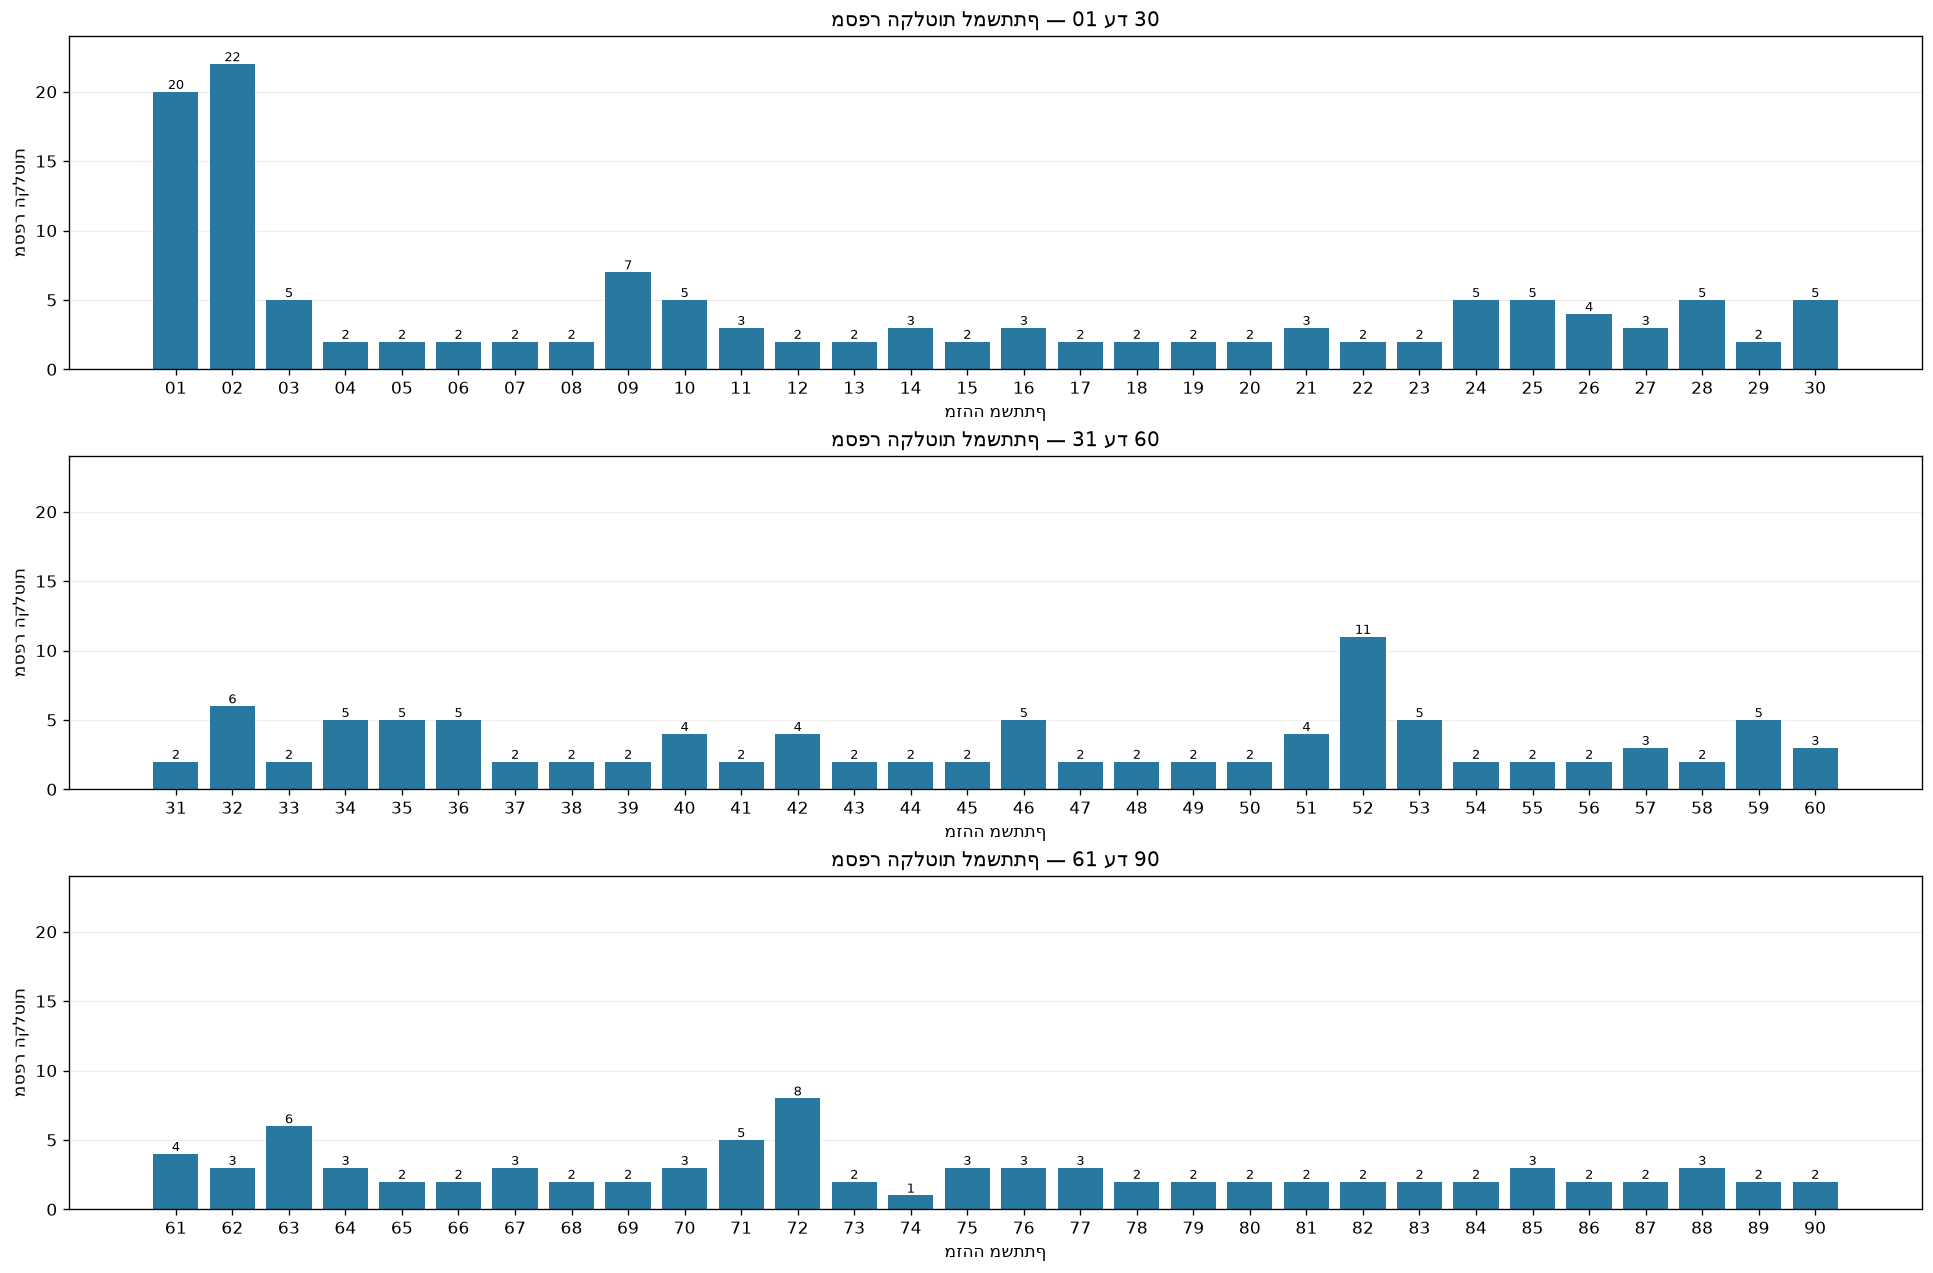

,הקלטות למשתתף
count,90.000000
mean,3.444444
std,3.116145
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,22.000000


In [5]:
plot_people = participants.assign(number=participants["participant"].str.extract(r"(\d+)$")[0].astype(int)).sort_values("number")
chunks = [plot_people.iloc[i:i+30] for i in range(0, len(plot_people), 30)]
fig, axes = plt.subplots(len(chunks), 1, figsize=(16, 3.5 * len(chunks)), squeeze=False, constrained_layout=True)
for ax, chunk in zip(axes.flat, chunks):
    ax.bar(chunk["number"].astype(str).str.zfill(2), chunk["n_recordings"], color="#2878a0")
    ax.set_ylim(0, plot_people["n_recordings"].max() + 2)
    ax.set_title(he(f'מספר הקלטות למשתתף — {chunk["number"].min():02d} עד {chunk["number"].max():02d}'))
    ax.set_xlabel(he("מזהה משתתף"))
    ax.set_ylabel(he("מספר הקלטות"))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    for i, value in enumerate(chunk["n_recordings"]):
        ax.text(i, value + 0.2, str(value), ha="center", fontsize=8)
plt.show()
display(participants["n_recordings"].describe().to_frame("הקלטות למשתתף"))


## התפלגות גיל המשתתפים

כל משתתף נספר פעם אחת, בלי קשר למספר ההקלטות שלו. הגרף משתמש בקבוצות גיל קבועות של עשר שנים; התוויות מציינות את הגילים הכלולים בכל קבוצה. גיל חסר אינו מומר לאפס, ומספר המשתתפים ללא גיל תקין מדווח בנפרד.

Missing ages: 0


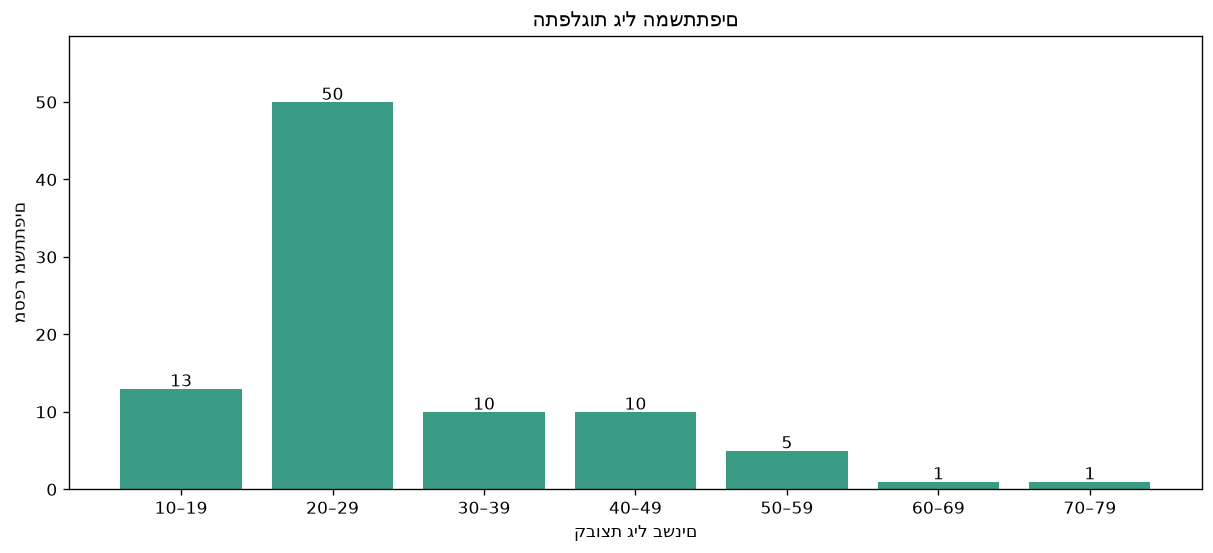

,גיל המשתתפים
count,90.000000
mean,28.411111
std,12.750761
min,13.000000
25%,21.000000
50%,23.000000
75%,33.500000
max,75.000000


In [6]:
ages = participants["age"].dropna().astype(int)
print("Missing ages:", participants["age"].isna().sum())
if ages.empty:
    raise ValueError("No valid participant ages to plot.")
start, stop = int(ages.min() // 10 * 10), int(ages.max() // 10 * 10 + 10)
bins = np.arange(start, stop + 1, 10)
labels = [f"{left}–{left+9}" for left in bins[:-1]]
age_counts = pd.cut(ages, bins=bins, labels=labels, right=False).value_counts(sort=False)
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.bar(labels, age_counts.to_numpy(), color="#399b83")
ax.set(title=he("התפלגות גיל המשתתפים"), xlabel=he("קבוצת גיל בשנים"), ylabel=he("מספר משתתפים"))
for i, value in enumerate(age_counts):
    ax.text(i, value + 0.3, str(value), ha="center")
ax.set_ylim(0, age_counts.max() * 1.15 + 1)
plt.show()
display(ages.describe().to_frame("גיל המשתתפים"))


## התפלגות המשתתפים לפי מין

ההתפלגות מתבססת על שדה Sex בקבצים, וכל משתתף נספר פעם אחת. כל קטגוריה לא מוכרת או חסרה נשמרת כקבוצה נפרדת; אין השלמת ערכים או הסקת מין מתוך נתונים אחרים.

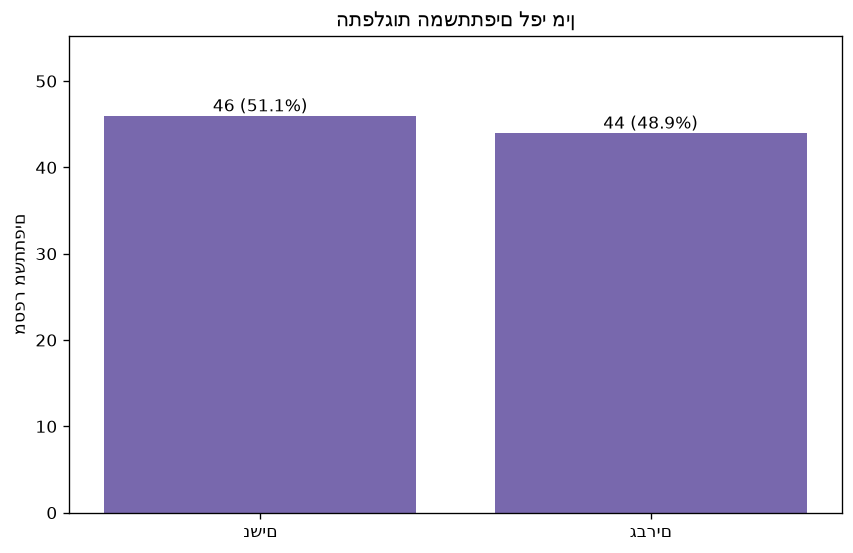

In [7]:
sex_labels = {"female": "נשים", "male": "גברים"}
sex_counts = participants["sex"].fillna("חסר").value_counts()
labels = [he(sex_labels.get(value, str(value))) for value in sex_counts.index]
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.bar(labels, sex_counts.to_numpy(), color="#7868ad")
ax.set(title=he("התפלגות המשתתפים לפי מין"), ylabel=he("מספר משתתפים"))
ax.set_ylim(0, sex_counts.max() * 1.2)
for i, value in enumerate(sex_counts):
    ax.text(i, value + 0.5, f"{value} ({100 * value / len(participants):.1f}%)", ha="center")
plt.show()


## משך ההקלטות והתפלגות האורכים

המשך מחושב לכל הקלטה מתוך HEA: מספר דגימות לכל ערוץ חלקי תדר הדגימה. שני הערוצים מייצגים אותו פרק זמן, ולכן אינם מכפילים את משך ההקלטה. אם כל ההקלטות באורך זהה, מוצגת עמודה יחידה — זהו ממצא ולא תקלה בגרף.

זהו משך לפי הכותרת, ולא אומדן של זמן אות נקי או של מספר פעימות שימושיות.

,מדד,ערך
0,מספר הקלטות,310.000000
1,משך מינימלי בשניות,20.000000
2,משך מקסימלי בשניות,20.000000
3,משך ממוצע בשניות,20.000000
4,חציון בשניות,20.000000
5,משך כולל בשניות,6200.000000
6,משך כולל בדקות,103.333333


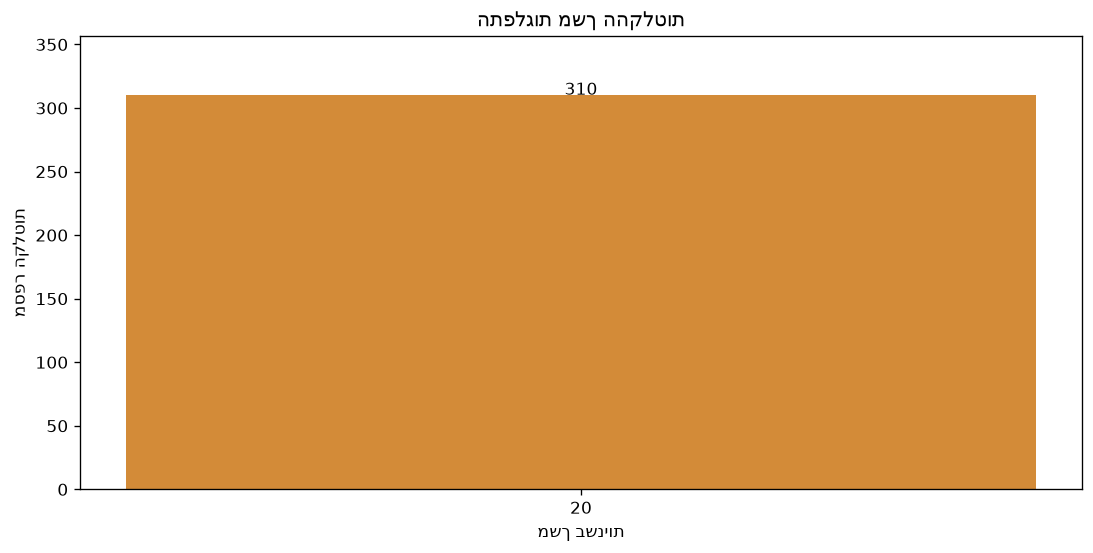

,sampling_rate_hz,n_samples,n_channels,n_recordings
0,500.0,10000,2,310


In [8]:
durations = recordings["duration_s"]
display(pd.DataFrame({
    "מדד": ["מספר הקלטות", "משך מינימלי בשניות", "משך מקסימלי בשניות",
             "משך ממוצע בשניות", "חציון בשניות", "משך כולל בשניות", "משך כולל בדקות"],
    "ערך": [len(durations), durations.min(), durations.max(), durations.mean(),
             durations.median(), durations.sum(), durations.sum()/60],
}))
counts = durations.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
if len(counts) <= 20:
    ax.bar([f"{value:g}" for value in counts.index], counts.to_numpy(), color="#d38b38", width=0.55)
    for i, value in enumerate(counts):
        ax.text(i, value + 0.5, str(value), ha="center")
    ax.set_ylim(0, counts.max() * 1.15)
else:
    ax.hist(durations, bins="auto", color="#d38b38", edgecolor="white")
ax.set(title=he("התפלגות משך ההקלטות"), xlabel=he("משך בשניות"), ylabel=he("מספר הקלטות"))
plt.show()
display(recordings.groupby(["sampling_rate_hz", "n_samples", "n_channels"]).size().reset_index(name="n_recordings"))


## קריאת אות ECG אמיתי וקובץ הסימונים

התא הבא קורא את קובץ DAT של ההקלטה הראשונה באמצעות ספריית WFDB ובודק שהממדים תואמים ל־HEA. הוא גם קורא את ATR, אם קיים. האות נשמר במשתנה `signal_record` לצורך חקירה עתידית; אין עיבוד, סינון או אימון מודל.

יחידות האות נלקחות מתוצאת WFDB, בלי להניח אותן ידנית. סימונים אוטומטיים אינם תוויות איכות שנבדקו ידנית. לא מוצג או נשמר תרשים של אות אישי, מאחר שהניתוח הנוכחי עוסק בהתפלגויות.

In [9]:
try:
    import wfdb
except ImportError:
    raise ImportError("Install wfdb using the installation cell above, then rerun this cell.")

example = recordings.iloc[0]
signal_record = wfdb.rdrecord(str(example["record_path"]), physical=True)
if signal_record.p_signal.shape != (int(example["n_samples"]), int(example["n_channels"])):
    raise ValueError("Signal dimensions do not match the parsed HEA metadata.")
if not np.isclose(signal_record.fs, example["sampling_rate_hz"]):
    raise ValueError("Sampling frequency differs between readers.")
print("Signal shape (samples, channels):", signal_record.p_signal.shape)
print("Channel names:", signal_record.sig_name)
print("Units reported by WFDB:", signal_record.units)
annotations = None
if example["atr_exists"]:
    annotations = wfdb.rdann(str(example["record_path"]), "atr")
    print("Annotation events:", len(annotations.sample))
    print("Annotation symbol counts:", dict(Counter(annotations.symbol)))


ImportError: Install wfdb using the installation cell above, then rerun this cell.

## מסקנות מהנתונים ומגבלות

התא הבא מפיק מסקנות מספריות מחדש מהטבלאות, ולא מסתמך על מספרים שהוקלדו מראש. במיפוי המקדים נמצאו 90 משתתפים ו־310 הקלטות, אך נתוני ההרצה הם הקובעים.

לפרויקט הזיהוי חשוב להפריד בין הקלטות: כל החלונות מאותה הקלטה צריכים להישאר באותה קבוצת אימון או בדיקה. רצוי גם ניסוי נפרד בין תאריכים. משתתף עם הקלטה אחת אינו מתאים להערכה הדורשת הקלטות נפרדות לאימון ולבדיקה. גיל ומין משמשים כאן לתיאור המאגר, ולא כתחליף לחתימת ECG.

המחברת אינה בודקת עדיין איכות אות בכל המאגר, אינה מאמתת ידנית את הסימונים ואינה מאמנת מודל. הערוצים המקורי והמסונן אינם דוגמאות עצמאיות. המאגר מכיל ECG במגע; אין כאן נתוני וידאו או מכ״ם להוכחת זיהוי מרחוק.

In [ ]:
print(f"משתתפים: {len(participants)}; הקלטות: {len(recordings)}")
print(f'מספר הקלטות למשתתף: {participants["n_recordings"].min()}–{participants["n_recordings"].max()}')
print(f'חציון הקלטות למשתתף: {participants["n_recordings"].median():g}')
print(f'משתתפים עם שתי הקלטות: {(participants["n_recordings"] == 2).sum()}')
print(f'משתתפים עם הקלטה יחידה: {(participants["n_recordings"] == 1).sum()}')
print(f'משתתפים עם יותר מתאריך תקין אחד: {(participants["n_dates"] > 1).sum()}')
print(f"גיל תקין: {len(ages)} משתתפים; טווח: {ages.min()}–{ages.max()}; חציון: {ages.median():g}")
print(f"סך משך ההקלטות: {durations.sum():g} שניות ({durations.sum()/60:.2f} דקות)")
if durations.nunique() == 1:
    print(f"כל ההקלטות באורך {durations.iloc[0]:g} שניות לפי הכותרות.")
print("מספר ההקלטות אינו מאוזן; יש לפרש ביצועים גם ברמת משתתף.")
print("ההתפלגות לפי מין כמעט מאוזנת בנתונים הנוכחיים, אך הגילים אינם מפוזרים באופן אחיד.")
